# Clustering Track — Indian Vehicle Registrations (2020–25)
23CSE301 ML Capstone

**K-Means** and **Agglomerative Hierarchical Clustering** on the [Indian Vehicle Registration Data (2020–25)](https://www.kaggle.com/datasets/aatifahmad123/indian-vehicle-registration-data-202025) (`data/raw/vehicle_registration/vehicle_registrations.csv`, 500,000 records). Each row is a group of vehicles registered in one month at one RTO with the same maker, model, fuel, class and emission norm, with `vehicleCount` vehicles in the group.

The goal is to find natural **vehicle segments** from vehicle characteristics (weight, fuel, emission norm, vehicle class, sale type, group size, year). There are no labels during training; the official vehicle category (`vehicleCategoryName`) is **held out and used only after clustering** to interpret/validate the clusters.

**Structure:** A (Dataset & EDA) → B (Preprocessing) → C (K-Means, Agglomerative) → D (Evaluation metrics) → E (Cluster visualisation) → F (Post-hoc validation).

## Section A — Dataset & EDA

### A1. Dataset Loading & Audit

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="colorblind")

DATA_PATH = Path("../data/raw/vehicle_registration/vehicle_registrations.csv")

# Filled in by Section C; keys must be exactly "K-Means" and "Agglomerative"
cluster_labels = {}

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.info()

Shape: (500000, 15)
<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype
---  ------                 --------------   -----
 0   registrationYear       500000 non-null  int64
 1   financialYear          500000 non-null  str  
 2   registrationMonthMMYY  500000 non-null  str  
 3   makerName              500000 non-null  str  
 4   stateName              500000 non-null  str  
 5   rtoCode                500000 non-null  str  
 6   rtoName                500000 non-null  str  
 7   vehicleCategoryName    500000 non-null  str  
 8   vehicleModelName       499994 non-null  str  
 9   fuelName               500000 non-null  str  
 10  vehicleClassName       500000 non-null  str  
 11  grossVehicleWeight     500000 non-null  int64
 12  pollutionNorm          500000 non-null  str  
 13  saleType               500000 non-null  str  
 14  vehicleCount           500000 non-null  int64
dtypes: int64

In [2]:
display(df.head())
print("Missing values per column (non-zero only):")
miss = df.isna().sum()
print(miss[miss > 0])
print("\nDuplicate rows:", df.duplicated().sum())
print("\nNumeric summary:")
display(df[["registrationYear", "grossVehicleWeight", "vehicleCount"]].describe().round(2))
print("registrationYear values outside 2020-2025:", (~df["registrationYear"].between(2020, 2025)).sum())
print("grossVehicleWeight == 0 (treated as missing):", (df["grossVehicleWeight"] == 0).sum())

,registrationYear,financialYear,registrationMonthMMYY,makerName,stateName,rtoCode,rtoName,vehicleCategoryName,vehicleModelName,fuelName,vehicleClassName,grossVehicleWeight,pollutionNorm,saleType,vehicleCount
0,2023,2022-2023,03-23,HYUNDAI MOTOR INDIA LTD,Punjab,PB19,RTO BARNALA,LIGHT MOTOR VEHICLE,CRETA 1.5 CRDI MT EX,DIESEL,Motor Car,1765,BHARAT STAGE VI,Resale,1
1,2022,2021-2022,03-22,TVS MOTOR COMPANY LTD,Odisha,OR26,NUAPADA RTO,TWO WHEELER(NT),TVS RADEON,PETROL,M-Cycle/Scooter,246,BHARAT STAGE VI,New,3
2,2020,2020-2021,12-20,TOYOTA KIRLOSKAR MOTOR PVT LTD,Karnataka,KA63,DHARWAD EAST RTO,LIGHT MOTOR VEHICLE,TOYOTA URBAN CRUISER (HIGH MT),PETROL,Motor Car,1600,BHARAT STAGE VI,New,2
3,2022,2022-2023,09-22,MARUTI SUZUKI INDIA LTD,Chhattisgarh,CG14,Jashpur DTO,LIGHT MOTOR VEHICLE,SWIFT LXI,PETROL,Motor Car,1335,BHARAT STAGE VI,New,1
4,2023,2023-2024,09-23,TATA MOTORS PASSENGER VEHICLES LTD,Karnataka,KA51,ELECTRONIC CITY RTO,LIGHT MOTOR VEHICLE,HARRIER XZ+ 2LBS6PH2 #DRK,DIESEL,Motor Car,2200,BHARAT STAGE VI,New,1


Missing values per column (non-zero only):
vehicleModelName    6
dtype: int64



Duplicate rows: 0

Numeric summary:


,registrationYear,grossVehicleWeight,vehicleCount
count,500000.00,500000.00,500000.00
mean,2022.82,1696.29,5.61
std,10.14,3861.62,23.52
min,2020.00,0.00,1.00
25%,2022.00,271.00,1.00
50%,2023.00,1185.00,1.00
75%,2024.00,1740.00,3.00
max,9100.00,108000.00,2078.00


registrationYear values outside 2020-2025: 5
grossVehicleWeight == 0 (treated as missing): 24238


**Data audit findings:** 500,000 records × 15 columns, essentially complete (only 6 missing `vehicleModelName`). Two data-quality issues are visible and handled in Section B: `registrationYear` contains impossible values (e.g. 9100, 2099) although the data covers 2020–25, and `grossVehicleWeight` is `0` for ~4.8 % of rows, which cannot be a real weight. `vehicleCount` (max 2,078, median 1) and `grossVehicleWeight` are extremely right-skewed.

### A2. EDA Visualisations

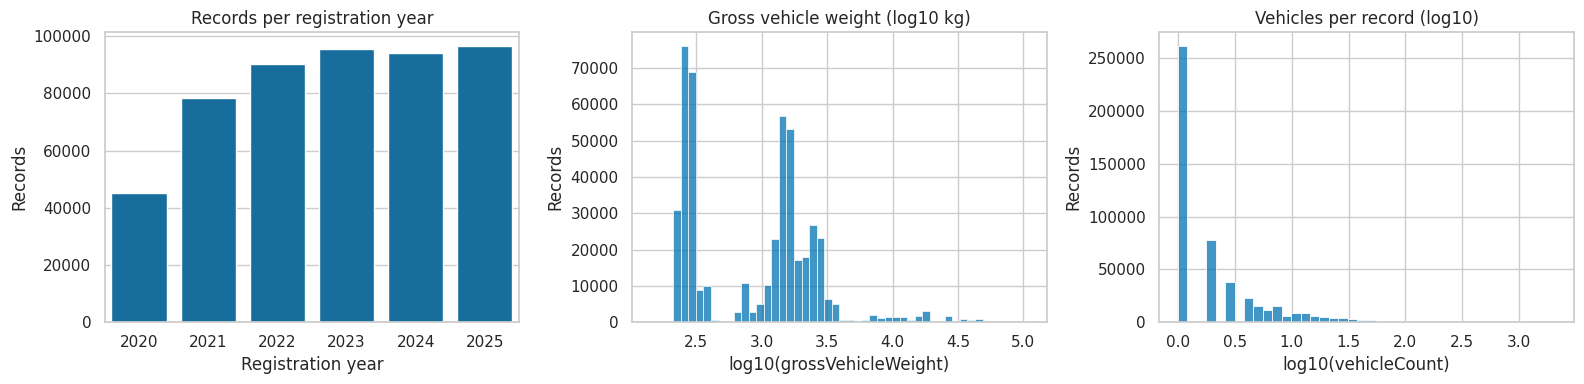

In [3]:
df_eda = df[df["registrationYear"].between(2020, 2025)]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df_eda, x="registrationYear", ax=axes[0])
axes[0].set_title("Records per registration year"); axes[0].set_xlabel("Registration year"); axes[0].set_ylabel("Records")
sns.histplot(np.log10(df_eda.loc[df_eda["grossVehicleWeight"] > 0, "grossVehicleWeight"]), bins=50, ax=axes[1])
axes[1].set_title("Gross vehicle weight (log10 kg)"); axes[1].set_xlabel("log10(grossVehicleWeight)"); axes[1].set_ylabel("Records")
sns.histplot(np.log10(df_eda["vehicleCount"]), bins=40, ax=axes[2])
axes[2].set_title("Vehicles per record (log10)"); axes[2].set_xlabel("log10(vehicleCount)"); axes[2].set_ylabel("Records")
plt.tight_layout(); plt.show()

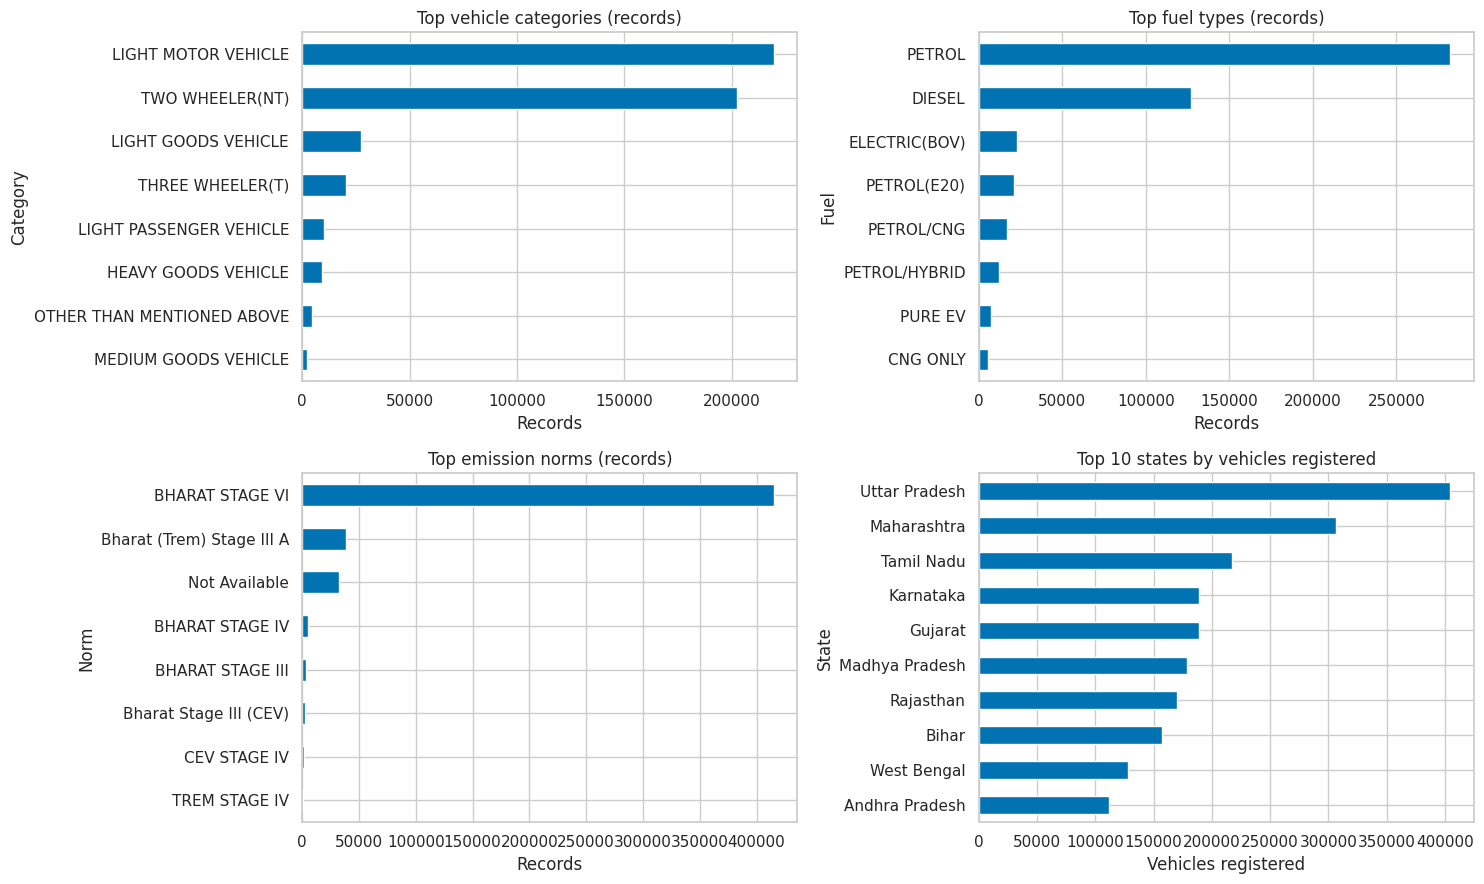

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
df_eda["vehicleCategoryName"].value_counts().head(8).plot(kind="barh", ax=axes[0, 0]).invert_yaxis()
axes[0, 0].set_title("Top vehicle categories (records)"); axes[0, 0].set_xlabel("Records"); axes[0, 0].set_ylabel("Category")
df_eda["fuelName"].value_counts().head(8).plot(kind="barh", ax=axes[0, 1]).invert_yaxis()
axes[0, 1].set_title("Top fuel types (records)"); axes[0, 1].set_xlabel("Records"); axes[0, 1].set_ylabel("Fuel")
df_eda["pollutionNorm"].value_counts().head(8).plot(kind="barh", ax=axes[1, 0]).invert_yaxis()
axes[1, 0].set_title("Top emission norms (records)"); axes[1, 0].set_xlabel("Records"); axes[1, 0].set_ylabel("Norm")
df_eda.groupby("stateName")["vehicleCount"].sum().sort_values(ascending=False).head(10).plot(kind="barh", ax=axes[1, 1]).invert_yaxis()
axes[1, 1].set_title("Top 10 states by vehicles registered"); axes[1, 1].set_xlabel("Vehicles registered"); axes[1, 1].set_ylabel("State")
plt.tight_layout(); plt.show()

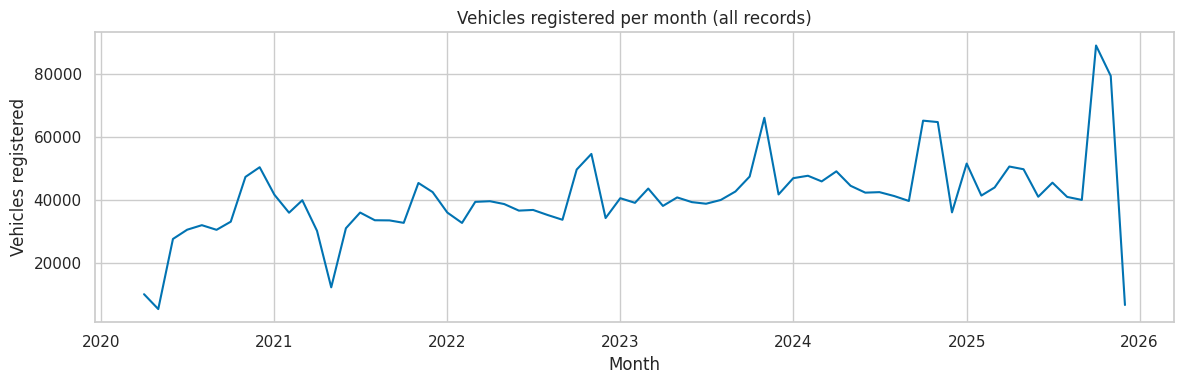

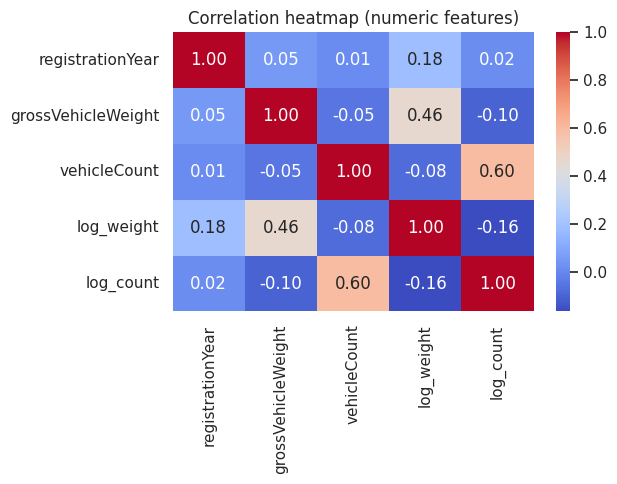

In [5]:
monthly = (df_eda.assign(month=pd.to_datetime(df_eda["registrationMonthMMYY"], format="%m-%y"))
                 .groupby("month")["vehicleCount"].sum())
plt.figure(figsize=(12, 4))
plt.plot(monthly.index, monthly.values)
plt.title("Vehicles registered per month (all records)"); plt.xlabel("Month"); plt.ylabel("Vehicles registered")
plt.tight_layout(); plt.show()

num_view = df_eda[["registrationYear", "grossVehicleWeight", "vehicleCount"]].assign(
    log_weight=np.log1p(df_eda["grossVehicleWeight"]), log_count=np.log1p(df_eda["vehicleCount"]))
plt.figure(figsize=(6.5, 5))
sns.heatmap(num_view.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap (numeric features)")
plt.tight_layout(); plt.show()

**Observation:** the data is dominated by two vehicle groups: light motor vehicles (~220k records) and non-transport two-wheelers (~202k) together make up about 85 % of the records, followed by light goods vehicles (~27k) and three-wheelers (~20k); the heavier categories are small. Petrol is the main fuel (~283k), then diesel (~127k), with electric and hybrid types as small but visible minorities, and Bharat Stage VI covers about 83 % of the records, as expected for vehicles registered after the 2020 norm change. Uttar Pradesh, Maharashtra and Tamil Nadu register the most vehicles. Monthly registrations rise from roughly 30–40k in 2020 to 40–50k, with a COVID-related dip in spring 2020 and again in mid-2021, recurring autumn festival-season peaks (the highest, about 89k, in autumn 2025), and a sharp drop in the final month, which looks like partial data. The numeric correlations are weak (e.g. log weight vs year 0.18, log weight vs log count −0.16), so the numeric features carry mostly independent information; the 0.60 and 0.46 correlations are just a variable with its own log transform.

## Section B — Preprocessing

Clustering is distance-based, so the data is cleaned and scaled first. All steps are explicit:

1. **Data quality:** keep `registrationYear` 2020–2025 (removes impossible years); treat `grossVehicleWeight == 0` as missing; drop duplicates.
2. **Features used:** `registrationYear`, `grossVehicleWeight`, `vehicleCount` (numeric) and `fuelName`, `pollutionNorm`, `saleType`, `vehicleClassName` (categorical). `vehicleClassName` has 67 values, so the 12 most common are kept and the rest grouped as `OTHER`. Identifiers and geography/time stamps (`rtoCode`, `rtoName`, `stateName`, `makerName`, `vehicleModelName`, `financialYear`, `registrationMonthMMYY`) are excluded so the clusters describe *vehicle characteristics*, not where/when they were registered.
3. **Held out:** `vehicleCategoryName` is kept aside as `y_true` and never used to fit anything.
4. **Transform:** median-impute numerics; `log1p` the heavily skewed `grossVehicleWeight` and `vehicleCount`; one-hot encode categoricals; standardise the **numeric** features only. The 0/1 dummy columns are deliberately left unscaled: standardising a dummy column inflates rare categories (a category present in 1 % of rows would get a z-score near 10), which lets a handful of rare vehicles dominate the distance.
5. **Subsample:** Agglomerative clustering needs O(n²) memory, so a fixed-seed random sample of `MAX_ROWS` records is used for both algorithms.

In [6]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

MAX_ROWS = 4000          # Agglomerative clustering is O(n^2) in memory
NUMERIC = ["registrationYear", "grossVehicleWeight", "vehicleCount"]
CATEGORICAL = ["fuelName", "pollutionNorm", "saleType", "vehicleClassName"]
LABEL_COL = "vehicleCategoryName"          # held out, used only in Section F

work = df[df["registrationYear"].between(2020, 2025)].drop_duplicates().copy()
work["grossVehicleWeight"] = work["grossVehicleWeight"].replace(0, np.nan)
top_classes = work["vehicleClassName"].value_counts().head(12).index
work["vehicleClassName"] = work["vehicleClassName"].where(work["vehicleClassName"].isin(top_classes), "OTHER")
print("Records after cleaning:", len(work))

work = work.sample(MAX_ROWS, random_state=RANDOM_STATE).reset_index(drop=True)
y_true = work[LABEL_COL]                                   # held out

X_num = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(work[NUMERIC]), columns=NUMERIC)
for col in ["grossVehicleWeight", "vehicleCount"]:         # heavy right skew -> log1p
    X_num[col] = np.log1p(X_num[col])
enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_cat = enc.fit_transform(work[CATEGORICAL])
feature_names = NUMERIC + list(enc.get_feature_names_out(CATEGORICAL))

X_scaled = np.hstack([StandardScaler().fit_transform(X_num.values), X_cat])   # numeric standardised, dummies left 0/1
df_model = work                                            # original-valued rows aligned with X_scaled (for profiling)
print("X_scaled shape:", X_scaled.shape)
print("Held-out label classes:", y_true.nunique())

Records after cleaning: 499995
X_scaled shape: (4000, 44)
Held-out label classes: 16


**Preprocessing justification:** clustering is distance-based, so each choice targets distance quality. Removing the impossible registration years (5 rows) and treating a weight of 0 as missing (about 24k rows, ≈ 4.8 %) avoids distances distorted by data-entry errors; median imputation keeps those records without inventing extreme values. Only vehicle-characteristic features were used (year, weight, group size, fuel, emission norm, sale type, vehicle class) so the clusters describe *types of vehicles* rather than where or when they were registered, and the official category was held out so it can serve as an independent check. `grossVehicleWeight` and `vehicleCount` are extremely right-skewed, so `log1p` stops a few heavy trucks or very large registration groups from dominating the distances. One-hot encoding is needed for the nominal categories, and grouping `vehicleClassName` into its top 12 values plus `OTHER` prevents dozens of near-empty dummy columns. Only the numeric features are standardised: scaling 0/1 dummies would inflate rare categories (a 1 % category gets a z-score near 10) and let a few unusual vehicles dominate. The 4,000-row sample is a practical limit because agglomerative clustering needs O(n²) memory.

## Section C — Clustering Algorithms

### C1. K-Means

The **Elbow curve** (inertia vs. k) is plotted alongside the silhouette score for each k; the k with the highest silhouette score is selected, then the final model is fitted.

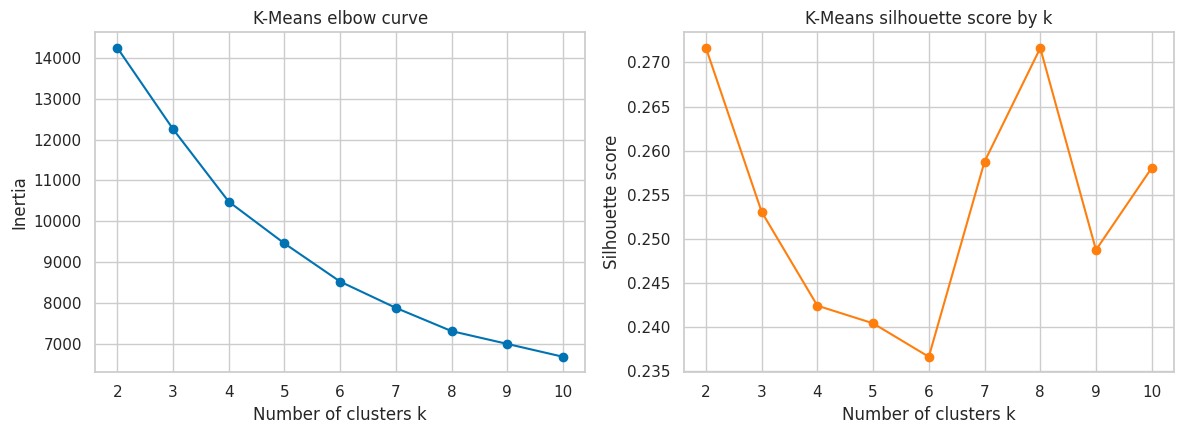

,k,inertia,silhouette
0,2,14247.2338,0.2717
1,3,12256.1532,0.2530
2,4,10478.3145,0.2424
3,5,9454.8144,0.2404
4,6,8519.8587,0.2366
5,7,7876.5982,0.2587
6,8,7307.9267,0.2716
7,9,6994.2346,0.2487
8,10,6678.8979,0.2580


In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = list(range(2, 11))
inertias, sils = [], []
for k in ks:
    km_k = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_scaled)
    inertias.append(km_k.inertia_)
    sils.append(silhouette_score(X_scaled, km_k.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(ks, inertias, marker="o")
axes[0].set_title("K-Means elbow curve"); axes[0].set_xlabel("Number of clusters k"); axes[0].set_ylabel("Inertia")
axes[1].plot(ks, sils, marker="o", color="tab:orange")
axes[1].set_title("K-Means silhouette score by k"); axes[1].set_xlabel("Number of clusters k"); axes[1].set_ylabel("Silhouette score")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"k": ks, "inertia": inertias, "silhouette": sils}).round(4))

In [8]:
best_k = ks[int(np.argmax(sils))]
km = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10).fit(X_scaled)
cluster_labels["K-Means"] = km.labels_
print(f"Selected k = {best_k} (highest silhouette). Cluster sizes:", np.bincount(km.labels_).tolist())

Selected k = 2 (highest silhouette). Cluster sizes: [1635, 2365]


**K-Means observation / choice of k:** the elbow curve decreases smoothly (inertia 14,247 at k = 2 down to 6,679 at k = 10) with no sharp bend, so it does not point to one clear k. The silhouette score is highest at k = 2 (0.2717), but k = 8 is practically tied (0.2716) and every k gives a score between 0.24 and 0.27. This means weak-to-moderate cluster structure and a coarse top-level split. Following the silhouette rule, k = 2 was selected (cluster sizes 1,635 and 2,365). It captures the broad division in the data, but a larger k (such as 8) is almost equally supported and would give finer segments.

### C2. Agglomerative Hierarchical Clustering

The **Dendrogram** (Ward linkage) is plotted, then the four linkage strategies are compared at the same k as K-Means. Linkages whose largest cluster holds more than 90 % of the points are treated as degenerate and not considered; among the rest the highest silhouette wins.

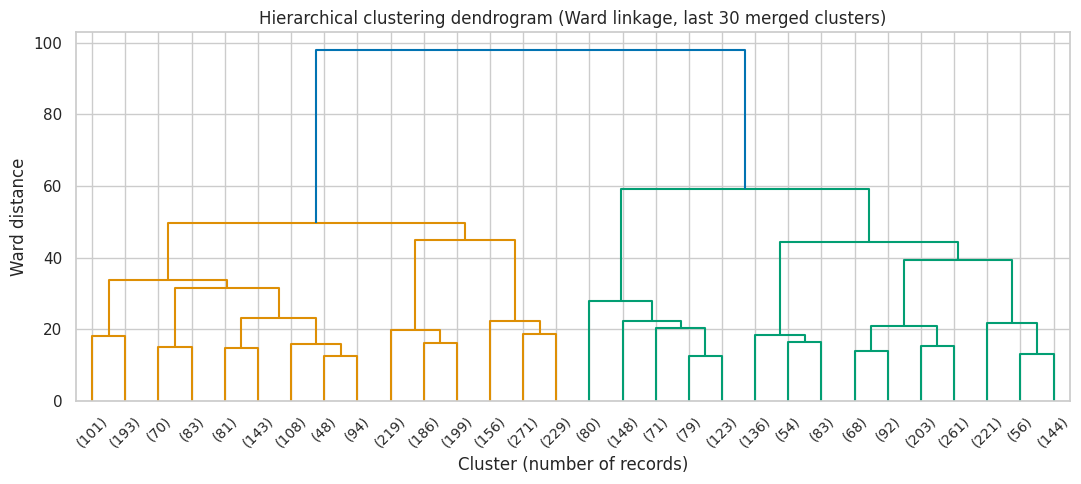

In [9]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(11, 5))
dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True)
plt.title("Hierarchical clustering dendrogram (Ward linkage, last 30 merged clusters)")
plt.xlabel("Cluster (number of records)"); plt.ylabel("Ward distance")
plt.tight_layout(); plt.show()

In [10]:
from sklearn.cluster import AgglomerativeClustering

rows, fits = [], {}
for method in ["ward", "complete", "average", "single"]:
    lab = AgglomerativeClustering(n_clusters=best_k, linkage=method).fit(X_scaled).labels_
    fits[method] = lab
    biggest = np.bincount(lab).max() / len(lab)
    rows.append({"linkage": method, "silhouette": silhouette_score(X_scaled, lab),
                 "largest cluster share": biggest, "degenerate (>90%)": biggest > 0.9})
linkage_table = pd.DataFrame(rows)
display(linkage_table.round(4))

valid = linkage_table[~linkage_table["degenerate (>90%)"]]
best_linkage = valid.loc[valid["silhouette"].idxmax(), "linkage"]
cluster_labels["Agglomerative"] = fits[best_linkage]
print(f"Selected linkage = {best_linkage}, k = {best_k}. Cluster sizes:", np.bincount(fits[best_linkage]).tolist())

,linkage,silhouette,largest cluster share,degenerate (>90%)
0,ward,0.2530,0.5452,False
1,complete,0.2855,0.9262,True
2,average,0.3828,0.9895,True
3,single,0.4953,0.9998,True


Selected linkage = ward, k = 2. Cluster sizes: [1819, 2181]


**Hierarchical observation / linkage comparison:** at k = 2, single, average and complete linkage report higher silhouette scores (0.495, 0.383, 0.286) than Ward (0.253), but they are degenerate: the largest cluster holds 99.98 %, 98.95 % and 92.6 % of the points, i.e. they just split off a few outliers and put everything else in one cluster, which inflates the silhouette without giving useful segments. Ward linkage, which merges clusters so as to minimise the increase in within-cluster variance, yields balanced clusters (1,819 and 2,181 points; largest share 54.5 %). Ward was therefore selected, in line with the rule that degenerate linkages are excluded.

## Section D — Evaluation Metrics

Silhouette Score, Davies-Bouldin Index and Calinski-Harabasz Index for **both** algorithms.

In [11]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

rows = []
for name, labels in cluster_labels.items():
    rows.append({
        "Algorithm": name,
        "Clusters": len(set(labels)),
        "Silhouette (higher better)": silhouette_score(X_scaled, labels),
        "Davies-Bouldin (lower better)": davies_bouldin_score(X_scaled, labels),
        "Calinski-Harabasz (higher better)": calinski_harabasz_score(X_scaled, labels),
    })
cluster_metrics = pd.DataFrame(rows)
display(cluster_metrics.round(4))

,Algorithm,Clusters,Silhouette (higher better),Davies-Bouldin (lower better),Calinski-Harabasz (higher better)
0,K-Means,2,0.2717,1.5350,1447.4482
1,Agglomerative,2,0.2530,1.6411,1315.0482


**Interpretation of the metrics:** K-Means is better on all three metrics: silhouette 0.2717 vs 0.2530, Davies-Bouldin 1.535 vs 1.641 (lower is better) and Calinski-Harabasz 1,447 vs 1,315. The metrics therefore agree, but the margins are modest. Silhouette values around 0.25–0.27 indicate only moderate separation (clusters are somewhat overlapping). K-Means directly optimises compactness around centroids, which these metrics reward, while Ward optimises a similar variance criterion, so it is expected that the two algorithms end up close. Overall, K-Means gives slightly tighter and better-separated clusters here, and a nested hierarchy (dendrogram) is the extra that agglomerative clustering offers.

## Section E — Cluster Visualisation

PCA-reduced 2-D scatter with cluster colour-coding for **every** algorithm, and a t-SNE plot for each algorithm.

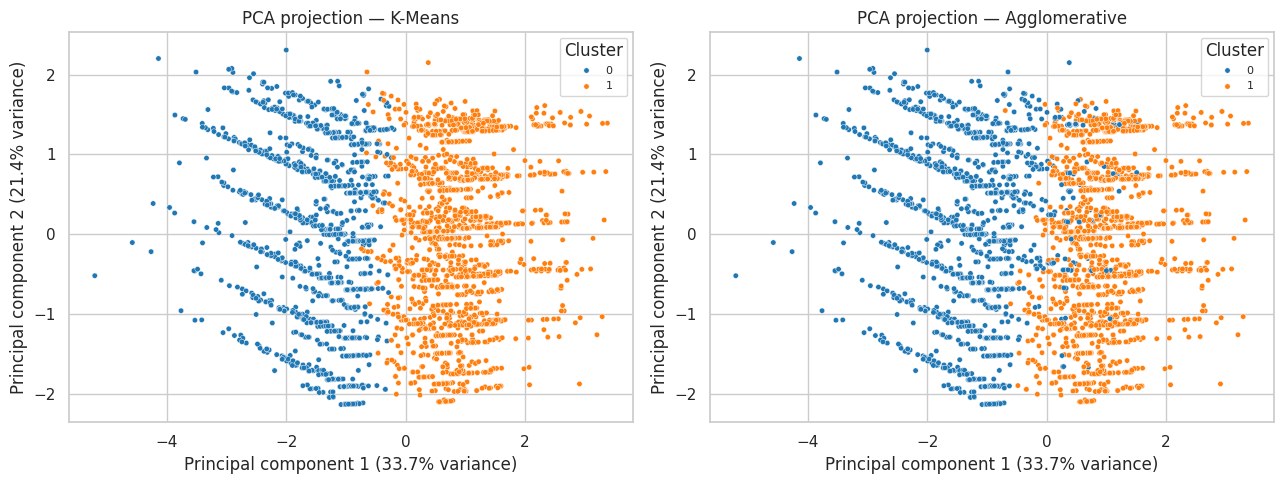

In [12]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_STATE)
pcs = pca.fit_transform(X_scaled)
fig, axes = plt.subplots(1, len(cluster_labels), figsize=(6.5 * len(cluster_labels), 5), squeeze=False)
for ax, (name, labels) in zip(axes[0], cluster_labels.items()):
    sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=labels, palette="tab10", s=15, ax=ax, legend="full")
    ax.set_title(f"PCA projection — {name}")
    ax.set_xlabel(f"Principal component 1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
    ax.set_ylabel(f"Principal component 2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
    ax.legend(title="Cluster", fontsize=8)
plt.tight_layout(); plt.show()

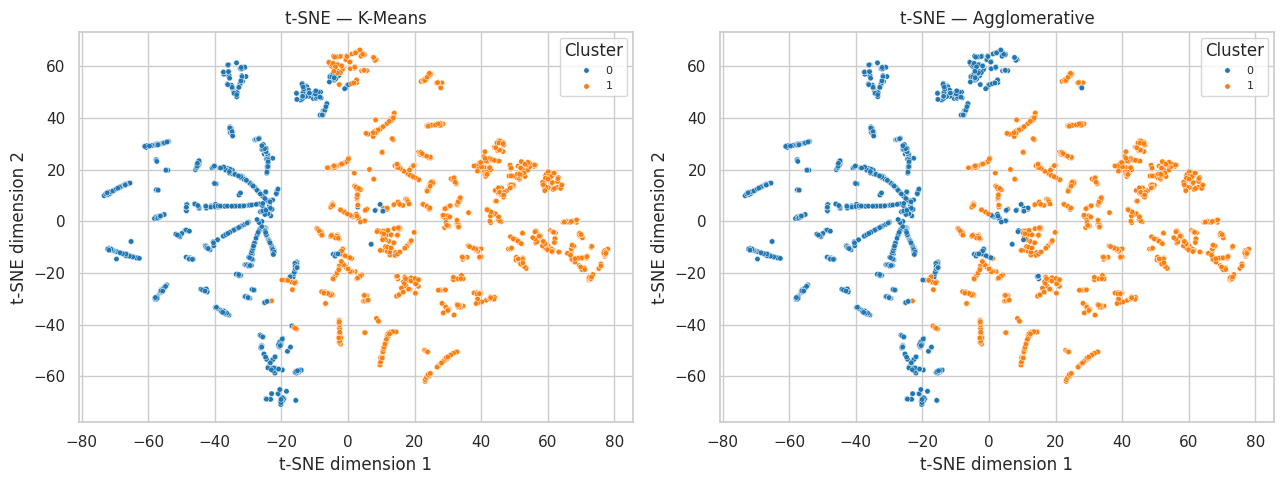

In [13]:
from sklearn.manifold import TSNE

emb = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30).fit_transform(X_scaled)
fig, axes = plt.subplots(1, len(cluster_labels), figsize=(6.5 * len(cluster_labels), 5), squeeze=False)
for ax, (name, labels) in zip(axes[0], cluster_labels.items()):
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=labels, palette="tab10", s=15, ax=ax, legend="full")
    ax.set_title(f"t-SNE — {name}")
    ax.set_xlabel("t-SNE dimension 1"); ax.set_ylabel("t-SNE dimension 2")
    ax.legend(title="Cluster", fontsize=8)
plt.tight_layout(); plt.show()

**Observation:** in the PCA plot (PC1 33.7 % + PC2 21.4 % = 55.1 % of the variance) the two clusters are separated mainly along PC1, with one cluster on the left and the other on the right, and they meet in a band near PC1 ≈ −0.5 to 0 where points of both colours overlap. The diagonal streaks are produced by the discrete one-hot combinations and the weight/count bands. The t-SNE plot separates the clusters more clearly: one cluster appears as many compact, elongated islands on the left and the other on the right, with only a few points of one colour inside the other's islands. K-Means and Agglomerative (Ward) give almost the same picture. The many small islands inside each cluster hint at finer sub-structure than k = 2 captures, consistent with the near-tie at k = 8 in the silhouette scores.

## Section F — Post-hoc Validation & Cluster Profiling

Only **after** clustering. Each cluster is profiled by size, mean numeric features and most common categorical values, and compared with the held-out official category (`vehicleCategoryName`) using Adjusted Rand Index, Normalised Mutual Information and a cross-tab of the largest categories. The label was never used while fitting.

In [14]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

top_cats = y_true.value_counts().head(6).index
for name, labels in cluster_labels.items():
    lab = np.asarray(labels)
    print(f"===== {name} =====")
    prof = df_model[["registrationYear", "grossVehicleWeight", "vehicleCount"]].groupby(lab).mean().round(1)
    prof.insert(0, "size", pd.Series(lab).value_counts().sort_index())
    for col in ["fuelName", "vehicleClassName", "pollutionNorm", "saleType"]:
        prof[f"top {col}"] = df_model.groupby(lab)[col].agg(lambda s: s.value_counts().index[0])
    display(prof)
    print(f"ARI vs vehicleCategoryName = {adjusted_rand_score(y_true, lab):.4f} | NMI = {normalized_mutual_info_score(y_true, lab):.4f}")
    display(pd.crosstab(lab, y_true.where(y_true.isin(top_cats), "OTHER CATEGORIES"), rownames=["cluster"], colnames=["official category"]))

===== K-Means =====


,size,registrationYear,grossVehicleWeight,vehicleCount,top fuelName,top vehicleClassName,top pollutionNorm,top saleType
0,1635,2022.9,294.0,10.5,PETROL,M-Cycle/Scooter,BHARAT STAGE VI,New
1,2365,2022.8,2916.7,2.0,DIESEL,Motor Car,BHARAT STAGE VI,New


ARI vs vehicleCategoryName = 0.6576 | NMI = 0.5987


official category,HEAVY GOODS VEHICLE,LIGHT GOODS VEHICLE,LIGHT MOTOR VEHICLE,LIGHT PASSENGER VEHICLE,OTHER CATEGORIES,THREE WHEELER(T),TWO WHEELER(NT)
cluster,,,,,,,
0,0,3,8,1,7,41,1575
1,74,195,1763,66,93,137,37


===== Agglomerative =====


,size,registrationYear,grossVehicleWeight,vehicleCount,top fuelName,top vehicleClassName,top pollutionNorm,top saleType
0,1819,2022.9,398.9,10.0,PETROL,M-Cycle/Scooter,BHARAT STAGE VI,New
1,2181,2022.8,3051.7,1.8,DIESEL,Motor Car,BHARAT STAGE VI,New


ARI vs vehicleCategoryName = 0.5954 | NMI = 0.5063


official category,HEAVY GOODS VEHICLE,LIGHT GOODS VEHICLE,LIGHT MOTOR VEHICLE,LIGHT PASSENGER VEHICLE,OTHER CATEGORIES,THREE WHEELER(T),TWO WHEELER(NT)
cluster,,,,,,,
0,1,7,104,1,9,128,1569
1,73,191,1667,66,91,50,43


**Post-hoc interpretation:** the two clusters split the data into light, high-volume vehicles and heavy, low-volume ones. K-Means cluster 0 (1,635 records) is **light two-wheelers**: mean weight ≈ 294 kg, large registration groups (mean count ≈ 10.5), petrol, M-Cycle/Scooter, BS-VI, new; 1,575 of its 1,635 records (96 %) are official "Two Wheeler (NT)" and it contains 98 % of all two-wheelers. Cluster 1 (2,365 records) is **cars and heavier vehicles**: mean weight ≈ 2,917 kg, small groups (mean count ≈ 2.0), mostly diesel Motor Cars; 1,763 records (75 %) are Light Motor Vehicles, plus most light and heavy goods vehicles and most three-wheelers. Agreement with the held-out category is ARI = 0.658 and NMI = 0.599 for K-Means, and ARI = 0.595 and NMI = 0.506 for Agglomerative, whose "two-wheeler" cluster is less pure because it also takes in 128 three-wheelers and 104 light motor vehicles. With only two clusters, minority categories (goods vehicles, three-wheelers) are merged with cars, so the agreement is driven by the two dominant categories. This is also not fully independent validation, because `vehicleClassName` is a feature and is closely related to the official category.

## Conclusion

**Problem.** Find natural segments of Indian vehicle registrations from vehicle characteristics only, without using labels, and use the official vehicle category afterwards to interpret the clusters.

**Data.** 500,000 records of vehicle groups (2020–25) with weight, fuel, emission norm, class, sale type, year and group size. After removing impossible years (5 rows) and treating zero weights as missing, a fixed-seed sample of 4,000 records was used (agglomerative clustering needs O(n²) memory). `log1p` was applied to the skewed features, the numeric features were standardised and the categoricals one-hot encoded.

**Method.** K-Means (elbow curve and silhouette over k = 2–10) and Agglomerative clustering (dendrogram and four linkages, degenerate ones excluded), evaluated with Silhouette, Davies-Bouldin and Calinski-Harabasz, visualised with PCA and t-SNE, and validated post hoc with ARI, NMI and cross-tabs against the held-out category.

**Results.** Both algorithms select k = 2. K-Means is slightly better on every metric (silhouette 0.272 vs 0.253; Davies-Bouldin 1.535 vs 1.641; Calinski-Harabasz 1,447 vs 1,315), though all silhouettes are modest. The two clusters are clearly interpretable: light, high-volume petrol two-wheelers versus heavy, low-volume, diesel-dominated cars and commercial vehicles. They agree well with the official category (K-Means ARI 0.66, NMI 0.60).

**Conclusion.** The dominant structure in the data is the two-wheeler vs four-wheeler divide, which K-Means recovers best. Finer segments such as goods vehicles, three-wheelers or electric vehicles are not resolved at k = 2; since k = 8 has almost the same silhouette and t-SNE shows many sub-islands, a larger k (with clustering on the full dataset) is the natural next step.